# Tweede Kamer Data Analysis

This notebook explores and analyzes data from the `tweedekamer.duckdb` file.

In [0]:
# Install DuckDB library
%pip install duckdb

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

def find_database(start: Path | None = None) -> Path:
    """Find the repository DuckDB database by walking up from the current folder."""
    current = (start or Path.cwd()).resolve()
    for folder in (current, *current.parents):
        candidate = folder / "tweedekamer.duckdb"
        if candidate.is_file():
            return candidate
    # Fallback: check known volume paths in Databricks
    fallback_paths = [
        Path("/Volumes/workspace/tweede-kamer/data_files/tweedekamer.duckdb"),
    ]
    for candidate in fallback_paths:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("Could not find tweedekamer.duckdb from the current directory")

database_path = find_database()
connection = duckdb.connect(str(database_path), read_only=True)

def query_df(sql: str, parameters=None) -> pd.DataFrame:
    """Execute a SQL query and return the result as a pandas DataFrame."""
    return connection.execute(sql, parameters or []).fetchdf()

database_path

PosixPath('/Volumes/workspace/tweede-kamer/data_files/tweedekamer.duckdb')

In [0]:
# List silver tables in the DuckDB database
tables = connection.execute("""
    SELECT table_schema, table_name
    FROM information_schema.tables
    WHERE table_type = 'BASE TABLE'
      AND table_schema = 'silver'
    ORDER BY table_name
""").fetchall()
print(f"Found {len(tables)} silver tables:\n")
for schema, name in tables:
    print(f"  - {schema}.{name}")

Found 53 silver tables:

  - silver.activiteit
  - silver.activiteit_actor
  - silver.activiteit_vervangen_vanuit
  - silver.activiteit_voortgezet_vanuit
  - silver.agendapunt
  - silver.besluit
  - silver.besluit_zaak
  - silver.commissie
  - silver.commissie_contactinformatie
  - silver.commissie_zetel
  - silver.commissie_zetel_vast_persoon
  - silver.commissie_zetel_vast_vacature
  - silver.commissie_zetel_vervanger_persoon
  - silver.commissie_zetel_vervanger_vacature
  - silver.document
  - silver.document_activiteit
  - silver.document_actor
  - silver.document_agendapunt
  - silver.document_bron_document
  - silver.document_publicatie
  - silver.document_publicatie_metadata
  - silver.document_versie
  - silver.document_zaak
  - silver.fractie
  - silver.fractie_zetel
  - silver.fractie_zetel_persoon
  - silver.fractie_zetel_vacature
  - silver.kamerstukdossier
  - silver.persoon
  - silver.persoon_contactinformatie
  - silver.persoon_geschenk
  - silver.persoon_loopbaan
  - si

In [0]:
# Get schema information for each table
for schema_name, table_name in tables:
    full_name = f"{schema_name}.{table_name}"
    print(f"\n{'='*60}")
    print(f"Table: {full_name}")
    print(f"{'='*60}")
    
    # Get column info
    schema = connection.execute(f"DESCRIBE {full_name}").fetchdf()
    print(schema.to_string(index=False))
    
    # Get row count
    row_count = connection.execute(f"SELECT COUNT(*) FROM {full_name}").fetchone()[0]
    print(f"\nRow count: {row_count:,}")


Table: silver.activiteit
                       column_name              column_type null  key default extra
                                id                  VARCHAR   NO  PRI    None  None
                             soort                  VARCHAR  YES None    None  None
                            nummer                  VARCHAR  YES None    None  None
                         onderwerp                  VARCHAR  YES None    None  None
                       datum_soort                  VARCHAR  YES None    None  None
                             datum                     DATE  YES None    None  None
                      aanvangstijd                TIMESTAMP  YES None    None  None
                          eindtijd                TIMESTAMP  YES None    None  None
                           locatie                  VARCHAR  YES None    None  None
                          besloten                  BOOLEAN  YES None    None  None
                            status                

## Preview Data from Each Table

Let's look at a sample of data from each table.

In [0]:
# Preview first 5 rows of each table
for schema_name, table_name in tables:
    full_name = f"{schema_name}.{table_name}"
    print(f"\n{'='*60}")
    print(f"Preview: {full_name}")
    print(f"{'='*60}")
    
    df = connection.execute(f"SELECT * FROM {full_name} LIMIT 5").fetchdf()
    display(df)


Preview: silver.activiteit


id,soort,nummer,onderwerp,datum_soort,datum,aanvangstijd,eindtijd,locatie,besloten,status,vergaderjaar,kamer,noot,vrs_nummer,sid_voortouw,voortouwnaam,voortouwafkorting,voortouwkortenaam,voortouwcommissie_id,aanvraagdatum,datum_verzoek_eerste_verlenging,datum_mededeling_eerste_verlenging,datum_verzoek_tweede_verlenging,datum_mededeling_tweede_verlenging,vervaldatum,gewijzigd_op,api_gewijzigd_op
a335f187-7a61-4ff1-9ecc-49b8333a8df6,Procedurevergadering,2015A05109,Procedurevergadering,Dag,2016-03-02T00:00:00.000Z,2016-03-02T14:00:00.000Z,2016-03-02T14:30:00.000Z,null,false,Uitgevoerd,2015-2016,Tweede Kamer,null,15736572,S-1-365867521-2120874753-4122826215-1100074744-145165186-3339216977,vaste commissie voor Koninkrijksrelaties,KR,KR,af1f56ee-1f1f-4bed-b0ab-31097ecdddef,null,null,null,null,null,null,2024-02-19T10:55:25.387Z,2024-02-19T12:24:15.236Z
a345c10d-a8a3-49dc-a612-0afe08c6b2fd,Algemeen overleg,2011A01966,Vreemdelingen- en Asielbeleid,Dag,2011-06-08T00:00:00.000Z,2011-06-08T16:30:00.000Z,2011-06-08T18:30:00.000Z,null,false,Uitgevoerd,2010-2011,Tweede Kamer,HERZIENE CONVOCATIE (agendapunten toegevoegd),15474708,S-1-365867521-2120874753-1106872067-1110798438-1073535367-1950654407,"algemene commissie voor Immigratie, Integratie en Asiel (2010-2012)",I&A (2010-2012),x - I&A (2010-2012),86cce16c-39ef-46bd-8fbe-4db6a57f433e,null,null,null,null,null,null,2024-08-19T11:08:42.123Z,2024-08-19T09:10:12.799Z
a34ba856-50a9-488b-a119-b710340b5fd7,Algemeen overleg,2018A00687,Voortgangsrapportage Nationaal Techniekpact 2020 - Is tot nader order uitgesteld,Dag,2018-04-24T00:00:00.000Z,2018-04-24T20:30:00.000Z,2018-04-24T23:30:00.000Z,null,false,Verplaatst,2017-2018,Tweede Kamer,Spreektijd per fractie maximaal 5 minuten,null,S-1-365867521-2120874753-699816589-1247091858-4091977384-2097348220,vaste commissie voor Economische Zaken en Klimaat (2017-2024),EZK (2017-2024),x - EZK (2017-2024),e1983fd8-9393-4814-8751-50f0d802a512,null,null,null,null,null,null,2024-08-19T11:08:45.540Z,2024-08-19T09:11:22.769Z
a36a7c3c-ee8e-4c0d-a1bf-0d97d1917336,Vergadering,2015A00077,Voorbereiding RTG/hoorzitting Integratie,Dag,2015-01-21T00:00:00.000Z,2015-01-21T18:30:00.000Z,2015-01-21T19:30:00.000Z,null,true,Uitgevoerd,2014-2015,Tweede Kamer,null,15693128,S-1-365867521-2120874753-3788684683-1120946898-3682340236-1101927899,vaste commissie voor Sociale Zaken en Werkgelegenheid,SZW,SZW,b18e6abf-15b8-445f-a177-e1823ee63424,null,null,null,null,null,null,2024-02-19T10:55:25.387Z,2024-02-19T10:13:23.889Z
a38f0474-b5d7-43c5-b6d8-81a8eee0917c,Werkbezoek,2013A00667,Kennismakingsbezoek/rondleiding ministerie BZK,Dag,2013-04-23T00:00:00.000Z,2013-04-23T18:30:00.000Z,2013-04-23T20:00:00.000Z,Ministerie BZK,true,Uitgevoerd,2012-2013,Tweede Kamer,null,null,S-1-365867521-2120874753-1888919946-1317393055-1476400269-2895261752,vaste commissie voor Binnenlandse Zaken,BiZa,BiZa,177eb895-6307-4268-94f6-a0f80dc3e358,null,null,null,null,null,null,2024-02-19T10:55:25.387Z,2024-02-19T11:17:06.502Z



Preview: silver.activiteit_actor


id,activiteit_id,commissie_id,persoon_id,fractie_id,actor_naam,actor_fractie,relatie,volgorde,functie,spreektijd,sid_actor,gewijzigd_op,api_gewijzigd_op
e58a01fa-245a-45a0-963f-9add6c063b03,bc4facf6-39aa-4be9-b947-339b14c9a2a0,befe416e-ca1b-4804-97d0-7aca1dcba888,null,null,"vaste commissie voor Volksgezondheid, Welzijn en Sport",null,Volgcommissie,1,null,null,S-1-365867521-2120874753-2028197338-1299813002-3981344915-3888665279,2023-09-06T12:03:49.420Z,2024-02-26T20:08:56.657Z
e591d7ab-3247-41c1-8b8a-8fdf19494160,63616be5-e1e6-4607-90ca-99328cd159f0,d38afba0-042f-4f3b-b0c8-b2df24eba6a7,null,null,vaste commissie voor Financiën,null,Volgcommissie,2,null,null,S-1-365867521-2120874753-701357190-1251517542-1254531773-1095447497,2009-09-25T14:48:45.160Z,2024-02-26T08:58:58.396Z
e62c4ebe-1c58-45b2-aed9-da09af4c9487,66631e33-4320-4188-bc3b-b298eaca67b0,b7cb67c2-71c7-478c-b3cf-1498e06f8f89,null,null,delegatie naar de NAVO-Assemblee,null,Volgcommissie,2,null,null,S-1-365867521-2120874753-1409024515-1293624399-3027757462-1629694323,2018-12-05T13:26:04.653Z,2024-02-26T15:48:31.390Z
e64298d0-2fa7-4164-9d1c-00ee12d6155c,6c0576ba-3248-41ff-ae8e-ea5784eb032e,e6291928-7ea0-46f9-aa6a-58b11ee069f2,null,null,algemene commissie voor Buitenlandse Handel en Ontwikkelingssamenwerking,null,Volgcommissie,2,null,null,S-1-365867521-2120874753-1804916992-1154416711-669633679-2938606454,2014-09-25T11:46:35.847Z,2024-02-26T12:24:53.428Z
e6947224-4f4d-4655-a884-03a7e8d2bbe5,63c6a555-09cb-4df1-a16f-0163e85fd67a,4e2ced14-ec17-43f1-8b5f-4eadc05b4589,null,null,vaste commissie voor Klimaat en Groene Groei,null,Volgcommissie,1,null,null,S-1-365867521-2120874753-2442999373-1297699589-2043061889-4086411752,2024-12-04T09:27:43.180Z,2024-12-04T08:27:54.013Z



Preview: silver.activiteit_vervangen_vanuit


...

zaak_id,gerelateerd_vanuit_id,relatie_gewijzigd_op
0f16f26c-5997-417c-a9d7-93dd8009f22c,0a43f1e4-e807-4a02-b1ae-f551887a40aa,2024-02-19T16:00:42.260Z
049b200b-b392-465a-a40d-14816903aad0,0b1dec38-1ab2-4c07-99e9-b8b1de59048e,2024-02-19T14:38:36.879Z
3a5764b6-26ba-4421-a2e5-93c05d66868a,0bc32350-e2c4-42ae-9b49-f2b896b37725,2024-02-19T12:55:43.548Z
37099d1f-1365-473f-86c1-8033cde976dc,0bf68250-f0f3-4961-86a3-f0680b34c580,2024-02-19T14:55:20.954Z
fa68762a-d86c-4eac-82a7-3f2aef1e8671,0c276bde-a387-4ba5-93cb-d6dd02f70314,2024-02-19T12:49:01.866Z



Preview: silver.zaak_vervangen_vanuit


zaak_id,vervangen_vanuit_id,relatie_gewijzigd_op
166912d7-92e4-49ba-8034-6acc54afbc93,00134bf0-9278-4654-8232-f4d2948e0363,2024-02-19T15:33:55.396Z
17aa9dc6-027d-4782-9361-3d729e7f2736,001f4d71-d4af-4662-8ce8-0c7ea6be03c2,2024-02-19T14:16:23.868Z
14cacddd-adfe-41bf-bfa9-b935a5d07899,00316e96-a0d5-429f-878a-5fa4c26be242,2024-02-19T14:35:33.940Z
dbac1f56-de61-4b15-a297-cf0f7792f81a,01fa89a5-1f7a-4ccd-b05f-072b592111cb,2024-02-19T14:33:26.654Z
824d4399-4bf0-4baa-b5b4-7b7f75a0f0bf,01ff5d4c-1f71-4c9b-89d1-6ba5d9382f85,2024-02-19T12:52:28.337Z



Preview: silver.zaal


id,naam,sys_code,gewijzigd_op,api_gewijzigd_op
0ad10e62-479e-45ec-8c89-b41ece33b880,Daleszaal,103,2021-06-15T13:19:04.140Z,2021-06-15T11:19:18.717Z
440a9af6-6028-4833-bbe1-2896f8e5a882,Koffiekamer,153,2019-08-12T12:56:35.330Z,2019-08-15T14:45:52.391Z
5df81c3f-5976-4689-abbb-4bf6ebe562bf,Rooksalon,56,2019-08-12T12:56:32.673Z,2019-08-15T14:45:51.047Z
8faebef7-9e47-4f39-a1f7-11f2e22feac6,Aletta Jacobszaal,77,2021-05-27T15:55:06.837Z,2021-05-27T13:56:00.015Z
a78a762d-6d94-4492-8ba8-d81e7bfec0fa,(Nog) geen zaal beschikbaar,240,2021-06-25T14:58:18.050Z,2021-06-25T12:59:02.900Z


## Convert to Spark DataFrames

Convert DuckDB tables to Spark DataFrames for analysis using Databricks capabilities.

In [0]:
# Convert all tables to Spark DataFrames and store in a dictionary
spark_tables = {}

for schema_name, table_name in tables:
    full_name = f"{schema_name}.{table_name}"
    print(f"Converting {full_name} to Spark DataFrame...")
    
    # Read from DuckDB
    pandas_df = connection.execute(f"SELECT * FROM {full_name}").fetchdf()
    
    # Convert to Spark
    spark_df = spark.createDataFrame(pandas_df)
    spark_tables[full_name] = spark_df
    
    print(f"  ✅ {full_name}: {len(pandas_df):,} rows, {len(pandas_df.columns)} columns")

print(f"\n✅ All {len(spark_tables)} tables converted to Spark DataFrames")

Converting silver.activiteit to Spark DataFrame...
  ✅ silver.activiteit: 73,243 rows, 28 columns
Converting silver.activiteit_actor to Spark DataFrame...
  ✅ silver.activiteit_actor: 301,551 rows, 14 columns
Converting silver.activiteit_vervangen_vanuit to Spark DataFrame...
  ✅ silver.activiteit_vervangen_vanuit: 5,894 rows, 3 columns
Converting silver.activiteit_voortgezet_vanuit to Spark DataFrame...
  ✅ silver.activiteit_voortgezet_vanuit: 619 rows, 3 columns
Converting silver.agendapunt to Spark DataFrame...
  ✅ silver.agendapunt: 321,042 rows, 12 columns
Converting silver.besluit to Spark DataFrame...
  ✅ silver.besluit: 669,643 rows, 10 columns
Converting silver.besluit_zaak to Spark DataFrame...
  ✅ silver.besluit_zaak: 669,643 rows, 3 columns
Converting silver.commissie to Spark DataFrame...
  ✅ silver.commissie: 132 rows, 17 columns
Converting silver.commissie_contactinformatie to Spark DataFrame...
  ✅ silver.commissie_contactinformatie: 458 rows, 7 columns
Converting silve

## Optional: Save to Delta Tables

Uncomment and run the cell below to save all tables as Delta tables in the `tweede-kamer` schema for better performance and persistence.

In [0]:
# Save all tables as Delta tables
# Uncomment the code below to save

# for table_name, spark_df in spark_tables.items():
#     print(f"Saving {table_name} as Delta table...")
#     spark_df.write.mode("overwrite").saveAsTable(f"workspace.`tweede-kamer`.{table_name}")
#     print(f"  ✅ Saved as workspace.tweede-kamer.{table_name}")
# 
# print(f"\n✅ All tables saved to workspace.tweede-kamer schema")

## Start Your Analysis Below

Use the `spark_tables` dictionary to access Spark DataFrames:
```python
# Example:
df = spark_tables['table_name']
df.show()
```

Or query directly from DuckDB:
```python
result = connection.execute("SELECT * FROM table_name WHERE ...").fetchdf()
display(result)
```

In [0]:
# People who have been in multiple fracties, showing all their distinct fracties
# PvdA, GL, GroenLinks-PvdA and PRO are treated as the same fractie under the name PRO
result = query_df("""
WITH normalized AS (
    SELECT
        p.id AS persoon_id,
        p.roepnaam, p.voornamen, p.tussenvoegsel, p.achternaam,
        CASE
            WHEN f.afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
            ELSE f.afkorting
        END AS fractie_norm
    FROM silver.persoon p
    JOIN silver.fractie_zetel_persoon fzp ON fzp.persoon_id = p.id
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN silver.fractie f ON f.id = fz.fractie_id
),
fractie_count AS (
    SELECT
        persoon_id,
        COUNT(DISTINCT fractie_norm) AS n_fracties
    FROM normalized
    GROUP BY persoon_id
    HAVING COUNT(DISTINCT fractie_norm) > 1
)
SELECT
    n.persoon_id,
    COALESCE(n.roepnaam, n.voornamen, '') 
        || COALESCE(' ' || NULLIF(n.tussenvoegsel, ''), '') 
        || ' ' || n.achternaam AS naam,
    string_agg(DISTINCT n.fractie_norm, ', ') AS fractie_afkortingen,
    COUNT(DISTINCT n.fractie_norm) AS aantal_fracties
FROM normalized n
WHERE n.persoon_id IN (SELECT persoon_id FROM fractie_count)
GROUP BY n.persoon_id, n.roepnaam, n.voornamen, n.tussenvoegsel, n.achternaam
ORDER BY n.achternaam
""")
print(f"Found {len(result)} people who switched fracties:")
display(result)

Found 49 people who switched fracties:


persoon_id,naam,fractie_afkortingen,aantal_fracties
e09e343b-09a0-4930-a43b-6b615002ddda,Gerard Van As,"Groep Nawijn, LPF",2
fac3056b-df3b-4712-9ae3-56472806747b,Martine Baay-Timmerman,"50PLUS/Baay-Timmerman, 50PLUS",2
eb86605b-38f2-4793-bd59-212c4ebbf4d4,Jhim van Bemmel,"Van Bemmel, PVV",2
c606904d-daef-44ff-bd30-cfdc1e6b5185,Louis Bontes,"GrBvK, PVV, BONTES",3
5c9533b7-a733-480e-bb38-711e96129684,Diederik Boomsma,"JA21, Nieuw Sociaal Contract",2
fdda013d-4d31-437b-a3d2-d388b3251915,Hero Brinkman,"BRINK, PVV",2
510ebeb6-5625-4a9f-9853-36bcd54728e0,René Claassen,"PVV, Groep Markuszower",2
c6e26bd3-724f-45d3-93af-ef431e6fcd42,Joost Eerdmans,"JA21, LPF, Groep Eerdmans-van Schijndel",3
d59d1492-57b6-482b-88b6-b2b77c45c33d,Olaf Ephraim,"FVD, Groep Van Haga, Ephraim",3
6e4a8d23-9d3b-4565-a3ab-086eb51d6c08,Derk Jan Eppink,"BBB, JA21",2


#Fractielid wisselingen
Deze grafiek laat ziet hoeveel leden verschillende fracties gemeen hebben gehad door de jaren heen. Mona Keijzer is bijvoorbeeld lid geweest can BBB, CDA en Lid Keijzer. Daarom zie je tussen de bolletjes van die 3 partijen lijntjes staan met 1. 
De grafiek is gesorteerd en gegroepeerd op basis van veel voorkomende overeenkomsten tussen partijen. Deze groeperingen kunnen op meerdere manieren verklaard worden, bijvoorbeeld doordat partijen veel gelijke standpunten hebben, of omdat er bij een afsplitsingspartij veel leden over zijn gestapt.

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


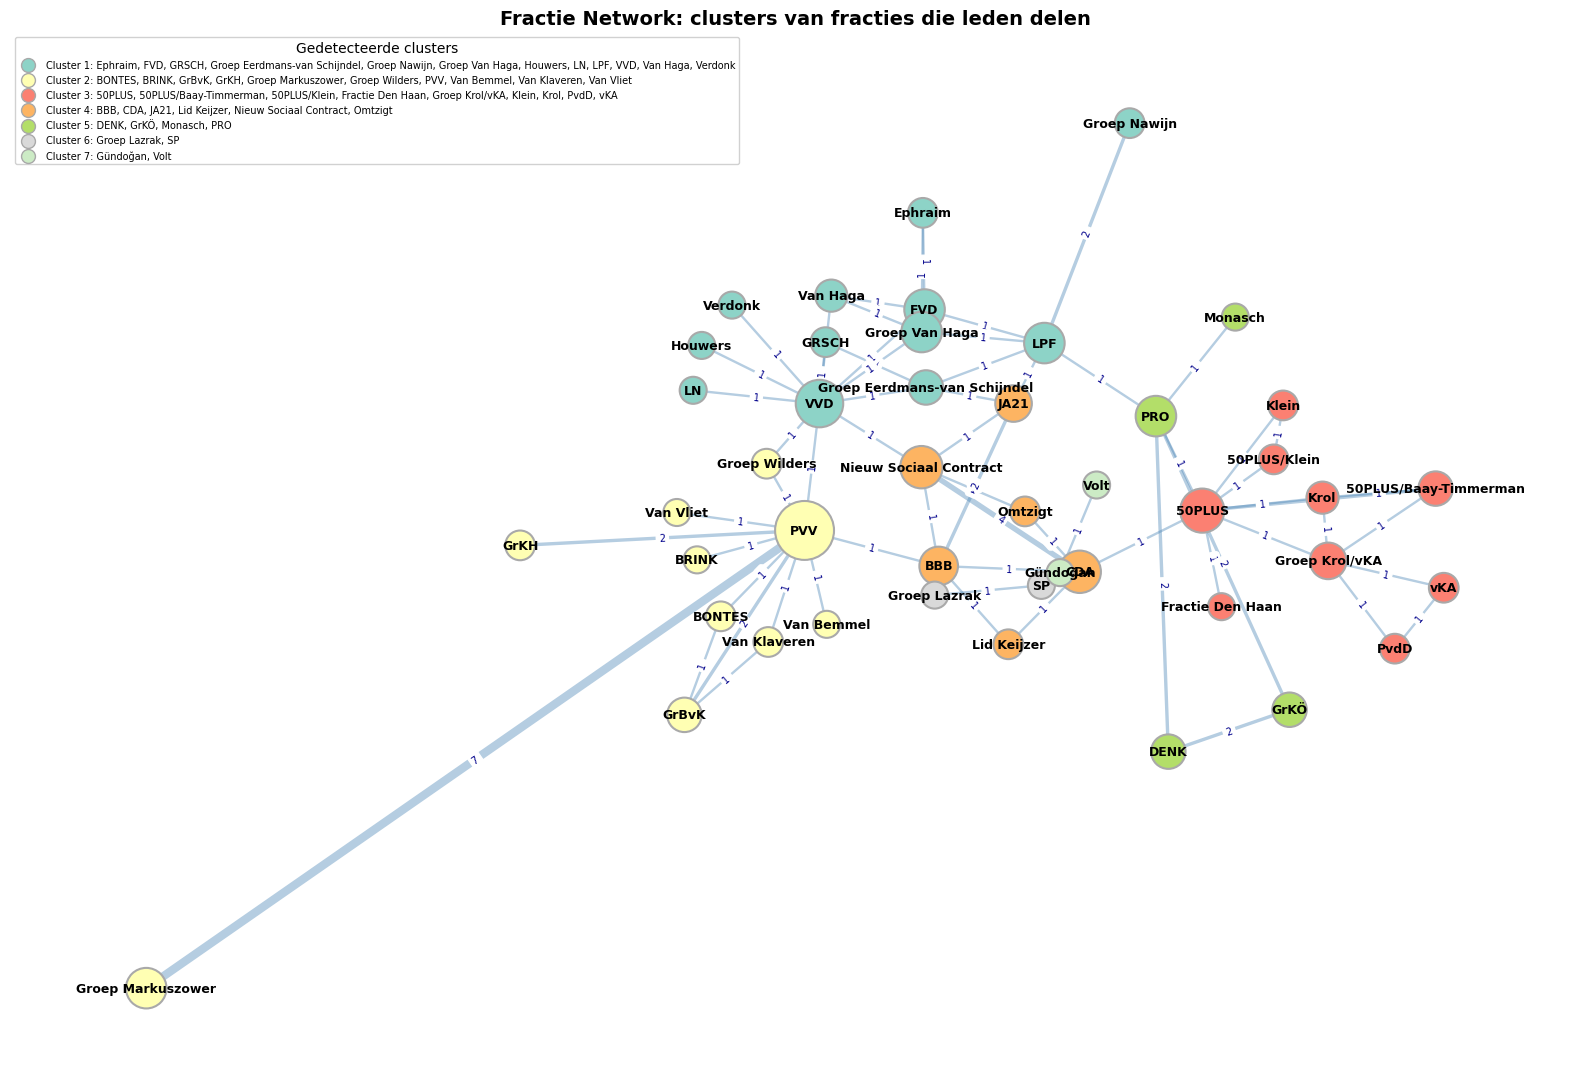


45 fracties, 66 verbindingen, 7 clusters
  Cluster 1 (12 fracties): Ephraim, FVD, GRSCH, Groep Eerdmans-van Schijndel, Groep Nawijn, Groep Van Haga, Houwers, LN, LPF, VVD, Van Haga, Verdonk
  Cluster 2 (10 fracties): BONTES, BRINK, GrBvK, GrKH, Groep Markuszower, Groep Wilders, PVV, Van Bemmel, Van Klaveren, Van Vliet
  Cluster 3 (9 fracties): 50PLUS, 50PLUS/Baay-Timmerman, 50PLUS/Klein, Fractie Den Haan, Groep Krol/vKA, Klein, Krol, PvdD, vKA
  Cluster 4 (6 fracties): BBB, CDA, JA21, Lid Keijzer, Nieuw Sociaal Contract, Omtzigt
  Cluster 5 (4 fracties): DENK, GrKÖ, Monasch, PRO
  Cluster 6 (2 fracties): Groep Lazrak, SP
  Cluster 7 (2 fracties): Gündoğan, Volt

Top 10 sterkste verbindingen:
  PVV <-> Groep Markuszower: 7 personen
  CDA <-> Nieuw Sociaal Contract: 4 personen
  FVD <-> Groep Van Haga: 3 personen
  50PLUS <-> 50PLUS/Baay-Timmerman: 2 personen
  BBB <-> JA21: 2 personen
  PVV <-> GrKH: 2 personen
  PVV <-> GrBvK: 2 personen
  LPF <-> Groep Nawijn: 2 personen
  PRO <-> DE

In [0]:
# Build a network graph of fracties connected by people who switched between them
# PvdA, GL, GroenLinks-PvdA and PRO are treated as the same fractie under the name PRO
# Communities are detected and color-coded to group tightly connected fracties together
import itertools

%pip install networkx -q
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities

# Get each person's distinct fracties (normalized)
persoon_fracties = query_df("""
WITH normalized AS (
    SELECT DISTINCT
        fzp.persoon_id,
        CASE
            WHEN f.afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
            ELSE f.afkorting
        END AS fractie
    FROM silver.fractie_zetel_persoon fzp
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN silver.fractie f ON f.id = fz.fractie_id
)
SELECT persoon_id, string_agg(fractie, '|') AS fracties
FROM normalized
GROUP BY persoon_id
""")

# Build edge weights: for each person with >1 fractie, connect all pairs
edge_weights = {}
for row in persoon_fracties.itertuples(index=False):
    fracties = sorted(set(row.fracties.split('|')))
    if len(fracties) > 1:
        for a, b in itertools.combinations(fracties, 2):
            edge_weights[(a, b)] = edge_weights.get((a, b), 0) + 1

# Build graph
G = nx.Graph()
for (a, b), weight in edge_weights.items():
    G.add_edge(a, b, weight=weight)

# Detect communities (clusters of tightly connected fracties)
communities = list(greedy_modularity_communities(G, weight='weight'))

color_map = plt.cm.Set3
community_colors = {}
for i, comm in enumerate(communities):
    for node in comm:
        community_colors[node] = color_map(i / max(len(communities), 1))

# Use Kamada-Kawai layout: pulls strongly connected nodes closer together
pos = nx.kamada_kawai_layout(G, weight='weight')

# Draw
fig, ax = plt.subplots(figsize=(16, 11))

edges = G.edges(data=True)
weights = [d['weight'] for _, _, d in edges]
max_w = max(weights) if weights else 1
edge_widths = [1 + 5 * (w / max_w) for w in weights]

degrees = dict(G.degree(weight='weight'))
node_sizes = [300 + 1500 * (degrees[n] / max(degrees.values())) for n in G.nodes]
node_colors = [community_colors[n] for n in G.nodes]

nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.4, edge_color='steelblue', ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, edgecolors='darkgray', linewidths=1.5, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', ax=ax)

# Edge labels showing switcher counts
edge_labels = {(a, b): d['weight'] for a, b, d in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels, font_size=7, font_color='darkblue', ax=ax)

# Legend for communities
for i, comm in enumerate(communities):
    ax.scatter([], [], c=[color_map(i / max(len(communities), 1))], s=100, edgecolors='darkgray',
               label=f"Cluster {i+1}: {', '.join(sorted(comm))}")
ax.legend(loc='upper left', fontsize=7, framealpha=0.9, title='Gedetecteerde clusters')

ax.set_title('Fractie Network: clusters van fracties die leden delen', fontsize=14, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

print(f"\n{len(G.nodes)} fracties, {len(G.edges)} verbindingen, {len(communities)} clusters")
for i, comm in enumerate(communities):
    print(f"  Cluster {i+1} ({len(comm)} fracties): {', '.join(sorted(comm))}")
print(f"\nTop 10 sterkste verbindingen:")
for a, b, w in sorted(G.edges(data=True), key=lambda x: -x[2]['weight'])[:10]:
    print(f"  {a} <-> {b}: {w['weight']} personen")

#Totaal aantal zetelwisselingen tegenover Gemiddeld aantal zetelwisselingen per jaar sinds bestaan.
Hier is te zien dat over het algemeen racties die langer bestaan meer zetelwisselingen hebben gehad totaal, maar het aantal zetewisselingen sinds de fractie bestaat zit geen patroon in.

Found 28 fracties with zetelwisselingen (2020–2026):


fractie,zetelwisselingen,aanmeldingen,vertrekken,jaren_bestaan
PRO,147,72.0,75.0,113.6
SGP,8,4.0,4.0,104.4
VVD,174,82.0,92.0,78.7
D66,125,66.0,59.0,60.0
CDA,83,41.0,42.0,46.0
SP,23,6.0,17.0,32.4
ChristenUnie,18,8.0,10.0,25.6
PvdD,33,16.0,17.0,19.9
PVV,85,42.0,43.0,19.9
FVD,51,28.0,23.0,9.5


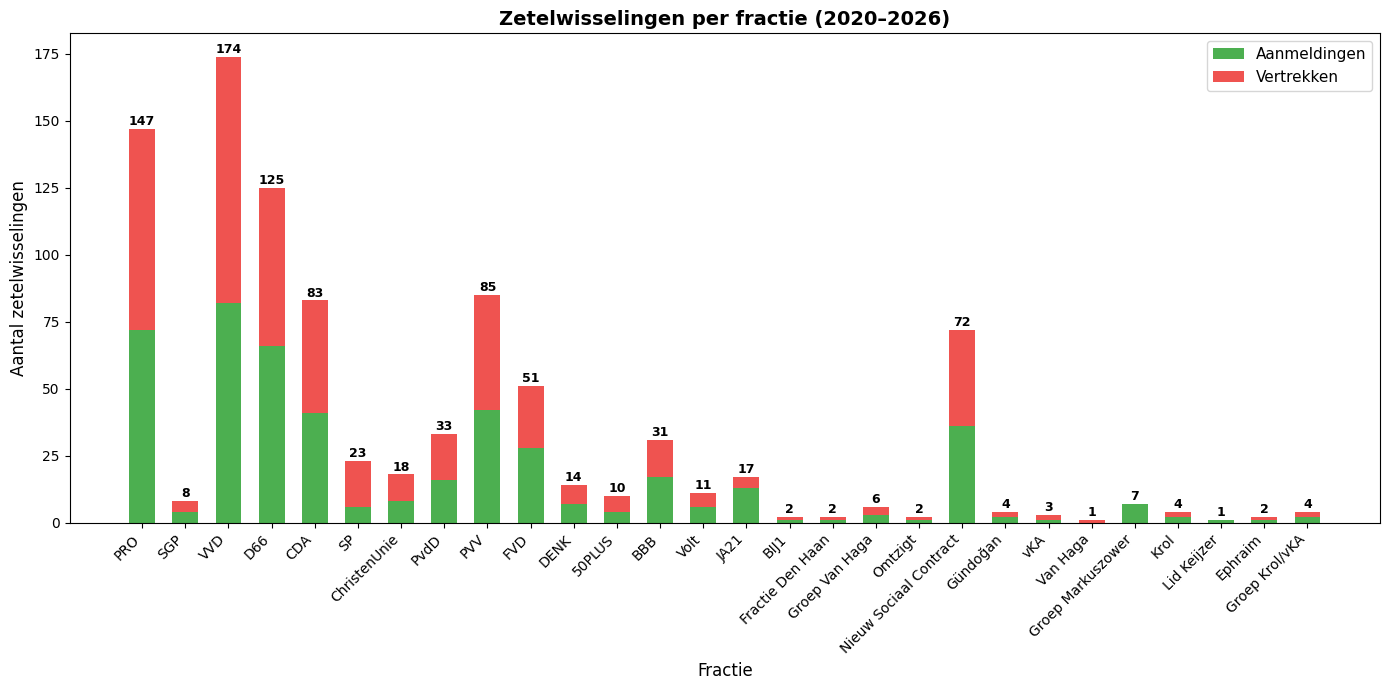

In [0]:
# Bar chart: zetelwisselingen (seat changes) per fractie, 2020–2026
# Counts both arrivals (van in range) and departures (tot_en_met in range)
# Only fracties that were active between 2020 and 2026 are included
# PvdA, GL, GroenLinks-PvdA and PRO are normalized to PRO

zetelwisselingen = query_df("""
WITH active_fracties AS (
    SELECT
        id,
        afkorting,
        naam_nl,
        datum_actief,
        datum_inactief,
        CASE
            WHEN afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
            ELSE afkorting
        END AS fractie_norm
    FROM silver.fractie
    WHERE datum_actief <= '2026-12-31'
      AND (datum_inactief IS NULL OR datum_inactief >= '2020-01-01')
),
seat_events AS (
    -- Arrivals: person joins a fractie
    SELECT
        f.fractie_norm,
        fzp.persoon_id,
        'Aanmelding' AS event_type,
        fzp.van AS event_date
    FROM silver.fractie_zetel_persoon fzp
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN active_fracties f ON f.id = fz.fractie_id
    WHERE fzp.van >= DATE '2020-01-01'
      AND fzp.van <= DATE '2026-12-31'

    UNION ALL

    -- Departures: person leaves a fractie
    SELECT
        f.fractie_norm,
        fzp.persoon_id,
        'Vertrek' AS event_type,
        fzp.tot_en_met AS event_date
    FROM silver.fractie_zetel_persoon fzp
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN active_fracties f ON f.id = fz.fractie_id
    WHERE fzp.tot_en_met IS NOT NULL
      AND fzp.tot_en_met >= DATE '2020-01-01'
      AND fzp.tot_en_met <= DATE '2026-12-31'
),
fractie_years AS (
    SELECT
        fractie_norm,
        SUM(
            GREATEST(
                DATE_DIFF('day', datum_actief, COALESCE(datum_inactief, DATE '2026-10-10')) / 365.25,
                0.01
            )
        ) AS jaren_bestaan
    FROM active_fracties
    GROUP BY fractie_norm
)
SELECT
    se.fractie_norm AS fractie,
    COUNT(*) AS zetelwisselingen,
    SUM(CASE WHEN event_type = 'Aanmelding' THEN 1 ELSE 0 END) AS aanmeldingen,
    SUM(CASE WHEN event_type = 'Vertrek' THEN 1 ELSE 0 END) AS vertrekken,
    ROUND(fy.jaren_bestaan, 1) AS jaren_bestaan
FROM seat_events se
JOIN fractie_years fy ON fy.fractie_norm = se.fractie_norm
GROUP BY se.fractie_norm, fy.jaren_bestaan
ORDER BY fy.jaren_bestaan DESC
""")

print(f"Found {len(zetelwisselingen)} fracties with zetelwisselingen (2020–2026):")
display(zetelwisselingen)

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(14, 7))

x = range(len(zetelwisselingen))
bar_width = 0.6

bars_aan = ax.bar(x, zetelwisselingen['aanmeldingen'], bar_width, label='Aanmeldingen', color='#4CAF50')
bar_vertrek = ax.bar(x, zetelwisselingen['vertrekken'], bar_width,
                      bottom=zetelwisselingen['aanmeldingen'], label='Vertrekken', color='#EF5350')

ax.set_xlabel('Fractie', fontsize=12)
ax.set_ylabel('Aantal zetelwisselingen', fontsize=12)
ax.set_title('Zetelwisselingen per fractie (2020–2026)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(zetelwisselingen['fractie'], rotation=45, ha='right', fontsize=10)
ax.legend(fontsize=11)

# Add total count labels on top of each bar
for i, total in enumerate(zetelwisselingen['zetelwisselingen']):
    ax.text(i, total + 0.3, str(total), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

Found 28 fracties:


fractie,zetelwisselingen,aanmeldingen,vertrekken,jaren_bestaan,wisselingen_per_jaar
PRO,532,276.0,256.0,113.6,4.68
SGP,17,10.0,7.0,104.4,0.16
VVD,462,242.0,220.0,78.7,5.87
D66,192,109.0,83.0,60.0,3.2
CDA,300,159.0,141.0,46.0,6.52
SP,123,63.0,60.0,32.4,3.8
ChristenUnie,59,31.0,28.0,25.6,2.31
PVV,155,87.0,68.0,19.9,7.8
PvdD,63,33.0,30.0,19.9,3.17
FVD,53,30.0,23.0,9.5,5.55


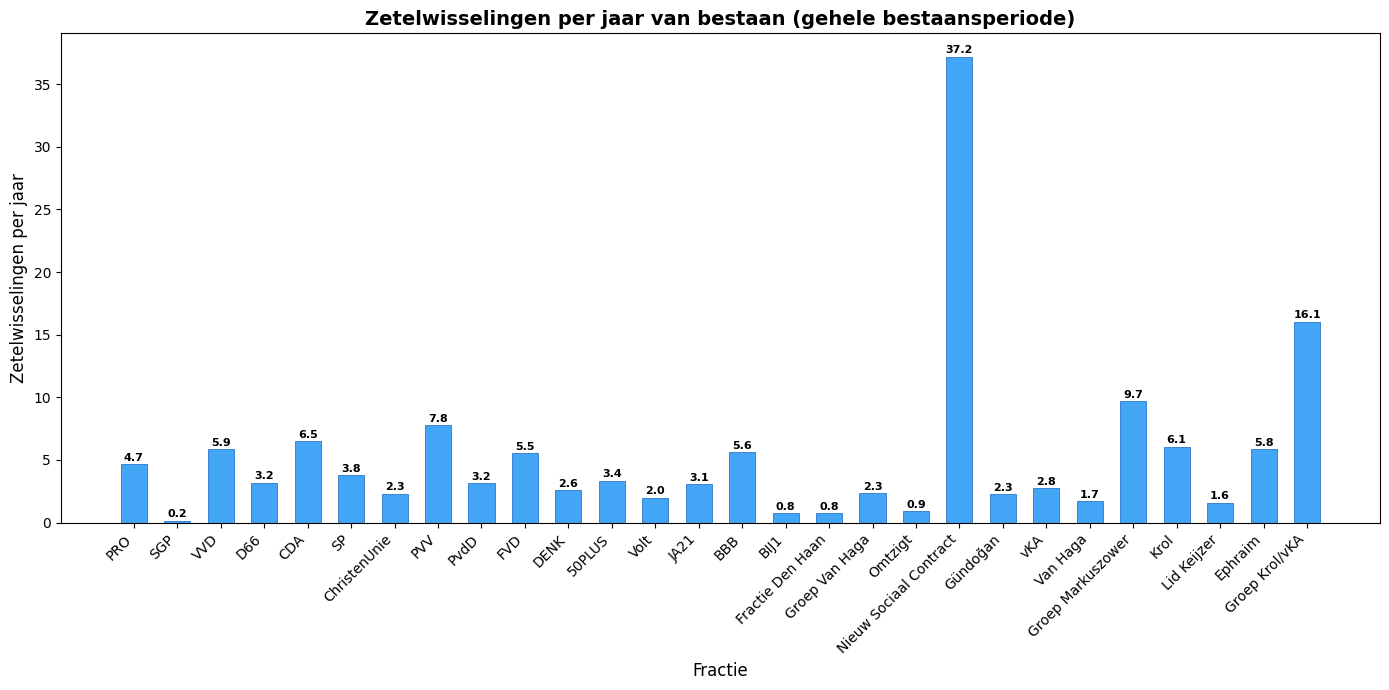

In [0]:
# Bar chart: zetelwisselingen per jaar van bestaan (entire existence, normalized)
# Same fracties as previous chart (active 2020–2026), PRO normalization applied
# Total seat changes (all-time) divided by years the fractie existed

wisselingen_per_jaar = query_df("""
WITH active_fracties AS (
    SELECT
        id,
        afkorting,
        naam_nl,
        datum_actief,
        datum_inactief,
        CASE
            WHEN afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
            ELSE afkorting
        END AS fractie_norm
    FROM silver.fractie
    WHERE datum_actief <= '2026-12-31'
      AND (datum_inactief IS NULL OR datum_inactief >= '2020-01-01')
),
-- Years of existence per normalized fractie (sum across constituent records)
fractie_years AS (
    SELECT
        fractie_norm,
        SUM(
            GREATEST(
                DATE_DIFF('day', datum_actief, COALESCE(datum_inactief, DATE '2026-10-10')) / 365.25,
                0.01
            )
        ) AS jaren_bestaan
    FROM active_fracties
    GROUP BY fractie_norm
),
-- All seat events across entire existence
seat_events AS (
    SELECT
        f.fractie_norm,
        'Aanmelding' AS event_type
    FROM silver.fractie_zetel_persoon fzp
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN active_fracties f ON f.id = fz.fractie_id
    WHERE fzp.van IS NOT NULL

    UNION ALL

    SELECT
        f.fractie_norm,
        'Vertrek' AS event_type
    FROM silver.fractie_zetel_persoon fzp
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN active_fracties f ON f.id = fz.fractie_id
    WHERE fzp.tot_en_met IS NOT NULL
),
event_counts AS (
    SELECT
        fractie_norm,
        COUNT(*) AS zetelwisselingen,
        SUM(CASE WHEN event_type = 'Aanmelding' THEN 1 ELSE 0 END) AS aanmeldingen,
        SUM(CASE WHEN event_type = 'Vertrek' THEN 1 ELSE 0 END) AS vertrekken
    FROM seat_events
    GROUP BY fractie_norm
)
SELECT
    ec.fractie_norm AS fractie,
    ec.zetelwisselingen,
    ec.aanmeldingen,
    ec.vertrekken,
    ROUND(fy.jaren_bestaan, 1) AS jaren_bestaan,
    ROUND(ec.zetelwisselingen / fy.jaren_bestaan, 2) AS wisselingen_per_jaar
FROM event_counts ec
JOIN fractie_years fy ON fy.fractie_norm = ec.fractie_norm
ORDER BY fy.jaren_bestaan DESC
""")

print(f"Found {len(wisselingen_per_jaar)} fracties:")
display(wisselingen_per_jaar)

# Plot bar chart
fig, ax = plt.subplots(figsize=(14, 7))

x = range(len(wisselingen_per_jaar))
bar_width = 0.6

bars = ax.bar(x, wisselingen_per_jaar['wisselingen_per_jaar'], bar_width, color='#42A5F5', edgecolor='#1565C0', linewidth=0.5)

ax.set_xlabel('Fractie', fontsize=12)
ax.set_ylabel('Zetelwisselingen per jaar', fontsize=12)
ax.set_title('Zetelwisselingen per jaar van bestaan (gehele bestaansperiode)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(wisselingen_per_jaar['fractie'], rotation=45, ha='right', fontsize=10)

# Add value labels on top of each bar
for i, val in enumerate(wisselingen_per_jaar['wisselingen_per_jaar']):
    ax.text(i, val + 0.1, f'{val:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

#Totaal zetels tegenover gemiddelde zetelwisseling.
Dit is moeilijk weer te geven omdat de meeste zetelwisselingen bij fracties gebeuren bij de verkiezingen. Verkiezingen gebeuren meestal niet elk jaar, maar toch is er wel een visualisatie gemaakt op jaar gemiddelde.

Found 28 fracties:


fractie,avg_zetels,actieve_jaren,avg_wisselingen_per_jaar,ratio
Ephraim,1.0,1,2.0,2.0
Groep Krol/vKA,2.0,1,4.0,2.0
Gündoğan,1.0,2,2.0,2.0
Krol,1.0,2,2.0,2.0
vKA,1.0,2,1.5,1.5
FVD,6.4,7,7.3,1.13
Nieuw Sociaal Contract,23.7,3,24.0,1.01
Groep Markuszower,7.0,1,7.0,1.0
Lid Keijzer,1.0,1,1.0,1.0
Van Haga,1.0,1,1.0,1.0


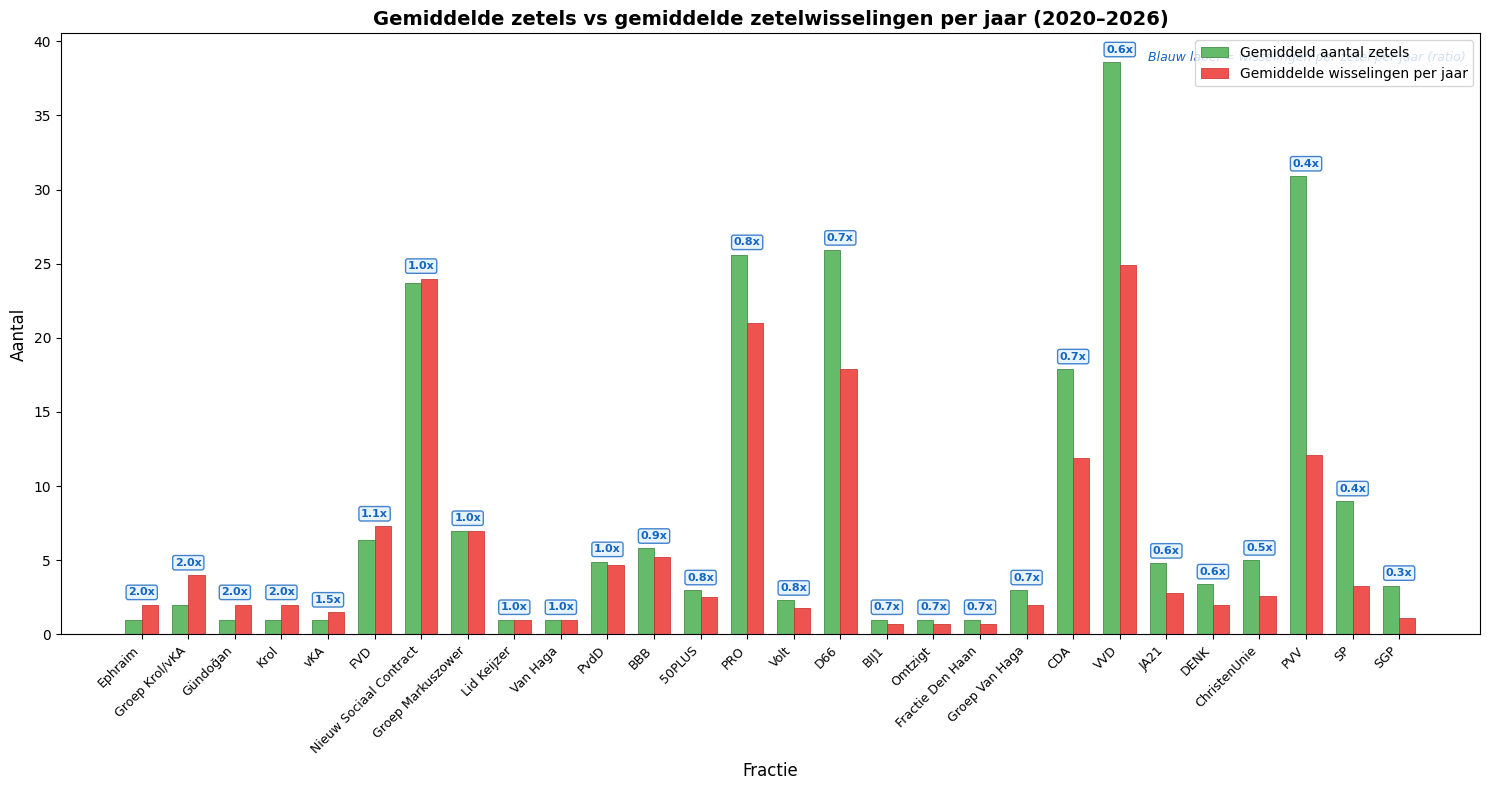

In [0]:
# Bar chart: ratio between average zetels and average zetelwisselingen per jaar (2020–2026)
# Avg zetels = average number of people holding a seat per year (2020–2026)
# Avg wisselingen = total seat changes / number of active years in range
# Only fracties active between 2020 and 2026, with PRO normalization

zetel_ratio = query_df("""
WITH active_fracties AS (
    SELECT
        id,
        afkorting,
        CASE
            WHEN afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
            ELSE afkorting
        END AS fractie_norm
    FROM silver.fractie
    WHERE datum_actief <= '2026-12-31'
      AND (datum_inactief IS NULL OR datum_inactief >= '2020-01-01')
),
-- Average zetels: count active members per year, then average across years
years AS (
    SELECT * FROM (VALUES (2020), (2021), (2022), (2023), (2024), (2025), (2026)) AS t(year_val)
),
yearly_zetels AS (
    SELECT
        f.fractie_norm,
        y.year_val,
        COUNT(DISTINCT fzp.persoon_id) AS n_zetels
    FROM active_fracties f
    JOIN silver.fractie_zetel fz ON fz.fractie_id = f.id
    JOIN silver.fractie_zetel_persoon fzp ON fzp.fractie_zetel_id = fz.id
    CROSS JOIN years y
    WHERE EXTRACT(YEAR FROM fzp.van) <= y.year_val
      AND (fzp.tot_en_met IS NULL OR EXTRACT(YEAR FROM fzp.tot_en_met) >= y.year_val)
    GROUP BY f.fractie_norm, y.year_val
),
avg_zetels AS (
    SELECT
        fractie_norm,
        AVG(n_zetels) AS avg_zetels,
        COUNT(*) AS n_active_years
    FROM yearly_zetels
    GROUP BY fractie_norm
),
-- Total zetelwisselingen 2020–2026
seat_events AS (
    SELECT f.fractie_norm
    FROM silver.fractie_zetel_persoon fzp
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN active_fracties f ON f.id = fz.fractie_id
    WHERE fzp.van >= DATE '2020-01-01' AND fzp.van <= DATE '2026-12-31'

    UNION ALL

    SELECT f.fractie_norm
    FROM silver.fractie_zetel_persoon fzp
    JOIN silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN active_fracties f ON f.id = fz.fractie_id
    WHERE fzp.tot_en_met IS NOT NULL
      AND fzp.tot_en_met >= DATE '2020-01-01'
      AND fzp.tot_en_met <= DATE '2026-12-31'
),
event_counts AS (
    SELECT fractie_norm, COUNT(*) AS zetelwisselingen
    FROM seat_events
    GROUP BY fractie_norm
)
SELECT
    az.fractie_norm AS fractie,
    ROUND(az.avg_zetels, 1) AS avg_zetels,
    az.n_active_years AS actieve_jaren,
    ROUND(COALESCE(ec.zetelwisselingen, 0) * 1.0 / az.n_active_years, 1) AS avg_wisselingen_per_jaar,
    ROUND(COALESCE(ec.zetelwisselingen, 0) * 1.0 / az.n_active_years / NULLIF(az.avg_zetels, 0), 2) AS ratio
FROM avg_zetels az
LEFT JOIN event_counts ec ON ec.fractie_norm = az.fractie_norm
WHERE az.avg_zetels > 0
ORDER BY ratio DESC
""")

print(f"Found {len(zetel_ratio)} fracties:")
display(zetel_ratio)

# Plot grouped bar chart with ratio annotations
fig, ax1 = plt.subplots(figsize=(15, 8))

x = list(range(len(zetel_ratio)))
bar_width = 0.35

bars1 = ax1.bar([i - bar_width/2 for i in x], zetel_ratio['avg_zetels'], bar_width,
                label='Gemiddeld aantal zetels', color='#66BB6A', edgecolor='#2E7D32', linewidth=0.5)
bars2 = ax1.bar([i + bar_width/2 for i in x], zetel_ratio['avg_wisselingen_per_jaar'], bar_width,
                label='Gemiddelde wisselingen per jaar', color='#EF5350', edgecolor='#C62828', linewidth=0.5)

ax1.set_xlabel('Fractie', fontsize=12)
ax1.set_ylabel('Aantal', fontsize=12)
ax1.set_title('Gemiddelde zetels vs gemiddelde zetelwisselingen per jaar (2020–2026)', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(zetel_ratio['fractie'], rotation=45, ha='right', fontsize=9)
ax1.legend(loc='upper right', fontsize=10)

# Annotate ratio above each pair of bars
for i, row in zetel_ratio.iterrows():
    max_h = max(row['avg_zetels'], row['avg_wisselingen_per_jaar'])
    ax1.text(i, max_h + 0.5, f"{row['ratio']:.1f}x",
             ha='center', va='bottom', fontsize=8, fontweight='bold',
             color='#1565C0',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='#E3F2FD', edgecolor='#1565C0', alpha=0.8))

ax1.text(0.99, 0.97, 'Blauw label = wisselingen per zetel per jaar (ratio)',
         transform=ax1.transAxes, fontsize=9, ha='right', va='top',
         style='italic', color='#1565C0')

plt.tight_layout()
plt.show()

# Gold Star Schema — Tweede Kamer Database

Dit is het **Gold-layer stermodel**: de brug-tabel `fractie_zetel` is geflattened,
zodat `dim_fractie` direct op de feit-tabel aansluit. De feit-tabel bevat één rij
per zetelwisseling-event (aanmelding of vertrek) met voorgecomputeerde afgeleide kolommen.
Kopieer de code hieronder naar [mermaid.live](https://mermaid.live) om het stermodel te visualiseren.

```mermaid
erDiagram
    FACT_ZETELWISSELING ||--o{ DIM_PERSOON : "persoon_id"
    FACT_ZETELWISSELING }o--|| DIM_FRACTIE : "fractie_id"
    FACT_ZETELWISSELING }o--|| DIM_TIJD : "datum_id"

    FACT_ZETELWISSELING {
        BIGINT event_id PK
        VARCHAR persoon_id FK
        VARCHAR fractie_id FK
        DATE datum_id FK
        VARCHAR event_type "aanmelding|vertrek"
        VARCHAR fractie_norm "PRO normalisatie"
        INTEGER jaar
        DOUBLE jaren_bestaan "op moment van event"
        INTEGER zetels_op_datum
    }

    DIM_PERSOON {
        VARCHAR id PK
        VARCHAR roepnaam
        VARCHAR voornamen
        VARCHAR tussenvoegsel
        VARCHAR achternaam
        VARCHAR geslacht
        DATE geboortedatum
        VARCHAR fractielabel
    }

    DIM_FRACTIE {
        VARCHAR id PK
        VARCHAR afkorting
        VARCHAR naam_nl
        VARCHAR fractie_norm "PRO normalisatie"
        INTEGER aantal_zetels
        DATE datum_actief
        DATE datum_inactief
        DOUBLE jaren_bestaan
    }

    DIM_TIJD {
        DATE datum_id PK
        INTEGER jaar
        INTEGER maand
        INTEGER kwartaal
        VARCHAR vergaderjaar
        VARCHAR maand_naam
    }
```

**Rol van elke tabel in het stermodel:**

| Tabel | Rol | Omschrijving |
| --- | --- | --- |
| `FACT_ZETELWISSELING` | **Feit (center)** | Één rij per zetelwisseling-event met meetwaarden (`zetels_op_datum`, `jaren_bestaan`) |
| `DIM_PERSOON` | **Dimensie** | Wie — persoonsgegevens (naam, geslacht, geboortedatum) |
| `DIM_FRACTIE` | **Dimensie** | Welke fractie — partijgegevens (afkorting, naam, zetels, bestaansduur) |
| `DIM_TIJD` | **Dimensie** | Wanneer — datumattributen (jaar, kwartaal, maand, vergaderjaar) |

**Verschillen met het Silver-model:**
- De brug-tabel `fractie_zetel` is verdwenen — `DIM_FRACTIE` koppelt direct aan de feit-tabel via `fractie_id`.
- De feit-tabel heet `FACT_ZETELWISSELING` (één rij per event, niet per seat-toewijzing).
- Een `DIM_TIJD` dimensie is toegevoegd voor tijd-gebaseerde analyses (jaar, kwartaal, vergaderjaar).
- Afgeleide kolommen (`fractie_norm`, `jaren_bestaan`, `zetels_op_datum`) zijn voorgecomputeerd in Gold.
- Tabelnamen volgen de `dim_` / `fact_` conventie.

In [0]:
# Create Gold-layer tables from the Silver schema
# Matches the star schema from the Mermaid diagram above
# Creates a separate DuckDB file for the Gold layer, attaching the source as read-only

gold_db_path = database_path.parent / "tweedekamer_gold.duckdb"
write_conn = duckdb.connect(str(gold_db_path))
write_conn.execute(f"ATTACH '{database_path}' AS src (READ_ONLY)")

def gold_query_df(sql):
    """Execute a SQL query on the Gold connection and return a DataFrame."""
    return write_conn.execute(sql).fetchdf()

# Create gold schema
write_conn.execute("CREATE SCHEMA IF NOT EXISTS gold")

# 1. dim_persoon
write_conn.execute("""
CREATE OR REPLACE TABLE gold.dim_persoon AS
SELECT
    id,
    roepnaam,
    voornamen,
    tussenvoegsel,
    achternaam,
    geslacht,
    geboortedatum,
    fractielabel
FROM src.silver.persoon
""")
print(f"dim_persoon:  {write_conn.execute('SELECT COUNT(*) FROM gold.dim_persoon').fetchone()[0]:,} rows")

# 2. dim_fractie (with PRO normalisation and jaren_bestaan)
write_conn.execute("""
CREATE OR REPLACE TABLE gold.dim_fractie AS
SELECT
    id,
    afkorting,
    naam_nl,
    CASE
        WHEN afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
        ELSE afkorting
    END AS fractie_norm,
    aantal_zetels,
    datum_actief,
    datum_inactief,
    ROUND(
        GREATEST(
            DATE_DIFF('day', datum_actief, COALESCE(datum_inactief, DATE '2026-10-10')) / 365.25,
            0.01
        ), 1
    ) AS jaren_bestaan
FROM src.silver.fractie
""")
print(f"dim_fractie:  {write_conn.execute('SELECT COUNT(*) FROM gold.dim_fractie').fetchone()[0]:,} rows")

# 3. dim_tijd (date dimension 2000–2026)
write_conn.execute("""
CREATE OR REPLACE TABLE gold.dim_tijd AS
SELECT
    d::DATE AS datum_id,
    EXTRACT(YEAR FROM d)::INTEGER AS jaar,
    EXTRACT(MONTH FROM d)::INTEGER AS maand,
    EXTRACT(QUARTER FROM d)::INTEGER AS kwartaal,
    CASE
        WHEN EXTRACT(MONTH FROM d) >= 9
        THEN EXTRACT(YEAR FROM d)::VARCHAR || '-' || (EXTRACT(YEAR FROM d) + 1)::VARCHAR
        ELSE (EXTRACT(YEAR FROM d) - 1)::VARCHAR || '-' || EXTRACT(YEAR FROM d)::VARCHAR
    END AS vergaderjaar,
    CASE EXTRACT(MONTH FROM d)
        WHEN 1 THEN 'januari' WHEN 2 THEN 'februari' WHEN 3 THEN 'maart'
        WHEN 4 THEN 'april' WHEN 5 THEN 'mei' WHEN 6 THEN 'juni'
        WHEN 7 THEN 'juli' WHEN 8 THEN 'augustus' WHEN 9 THEN 'september'
        WHEN 10 THEN 'oktober' WHEN 11 THEN 'november' WHEN 12 THEN 'december'
    END AS maand_naam
FROM generate_series(DATE '2000-01-01', DATE '2026-12-31', INTERVAL '1 day') AS t(d)
""")
print(f"dim_tijd:     {write_conn.execute('SELECT COUNT(*) FROM gold.dim_tijd').fetchone()[0]:,} rows")

# 4. fact_zetelwisseling (flattened: one row per event, fractie_id direct, no bridge)
write_conn.execute("""
CREATE OR REPLACE TABLE gold.fact_zetelwisseling AS
WITH aanmeldingen AS (
    SELECT
        fzp.persoon_id,
        f.id AS fractie_id,
        fzp.van AS datum_id,
        'aanmelding' AS event_type,
        CASE
            WHEN f.afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
            ELSE f.afkorting
        END AS fractie_norm,
        EXTRACT(YEAR FROM fzp.van)::INTEGER AS jaar,
        GREATEST(
            DATE_DIFF('day', f.datum_actief, COALESCE(f.datum_inactief, DATE '2026-10-10')) / 365.25,
            0.01
        ) AS jaren_bestaan
    FROM src.silver.fractie_zetel_persoon fzp
    JOIN src.silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN src.silver.fractie f ON f.id = fz.fractie_id
    WHERE fzp.van IS NOT NULL
),
vertrekken AS (
    SELECT
        fzp.persoon_id,
        f.id AS fractie_id,
        fzp.tot_en_met AS datum_id,
        'vertrek' AS event_type,
        CASE
            WHEN f.afkorting IN ('PvdA', 'GL', 'GroenLinks-PvdA', 'PRO') THEN 'PRO'
            ELSE f.afkorting
        END AS fractie_norm,
        EXTRACT(YEAR FROM fzp.tot_en_met)::INTEGER AS jaar,
        GREATEST(
            DATE_DIFF('day', f.datum_actief, COALESCE(f.datum_inactief, DATE '2026-10-10')) / 365.25,
            0.01
        ) AS jaren_bestaan
    FROM src.silver.fractie_zetel_persoon fzp
    JOIN src.silver.fractie_zetel fz ON fz.id = fzp.fractie_zetel_id
    JOIN src.silver.fractie f ON f.id = fz.fractie_id
    WHERE fzp.tot_en_met IS NOT NULL
),
all_events AS (
    SELECT * FROM aanmeldingen
    UNION ALL
    SELECT * FROM vertrekken
)
SELECT
    ROW_NUMBER() OVER (ORDER BY datum_id)::BIGINT AS event_id,
    persoon_id,
    fractie_id,
    datum_id,
    event_type,
    fractie_norm,
    jaar,
    ROUND(jaren_bestaan, 1) AS jaren_bestaan,
    -- zetels_op_datum: count active members in this fractie on the event date
    (
        SELECT COUNT(DISTINCT fzp2.persoon_id)
        FROM src.silver.fractie_zetel_persoon fzp2
        JOIN src.silver.fractie_zetel fz2 ON fz2.id = fzp2.fractie_zetel_id
        WHERE fz2.fractie_id = all_events.fractie_id
          AND fzp2.van <= all_events.datum_id
          AND (fzp2.tot_en_met IS NULL OR fzp2.tot_en_met >= all_events.datum_id)
    ) AS zetels_op_datum
FROM all_events
ORDER BY datum_id
""")
print(f"fact_zetelwisseling: {write_conn.execute('SELECT COUNT(*) FROM gold.fact_zetelwisseling').fetchone()[0]:,} rows")

# Show sample data from each Gold table
print("\n" + "="*60)
print("Sample: gold.dim_persoon (5 rows)")
display(gold_query_df("SELECT * FROM gold.dim_persoon LIMIT 5"))

print("\n" + "="*60)
print("Sample: gold.dim_fractie (5 rows)")
display(gold_query_df("SELECT * FROM gold.dim_fractie LIMIT 5"))

print("\n" + "="*60)
print("Sample: gold.dim_tijd (5 rows)")
display(gold_query_df("SELECT * FROM gold.dim_tijd LIMIT 5"))

print("\n" + "="*60)
print("Sample: gold.fact_zetelwisseling (10 rows)")
display(gold_query_df("SELECT * FROM gold.fact_zetelwisseling LIMIT 10"))

# Verify the star schema works: same zetelwisselingen per fractie as the EDA
print("\n" + "="*60)
print("Verification: zetelwisselingen per fractie (2020–2026) from Gold tables")
gold_check = gold_query_df("""
SELECT
    f.fractie_norm AS fractie,
    COUNT(*) AS zetelwisselingen,
    SUM(CASE WHEN fz.event_type = 'aanmelding' THEN 1 ELSE 0 END) AS aanmeldingen,
    SUM(CASE WHEN fz.event_type = 'vertrek' THEN 1 ELSE 0 END) AS vertrekken
FROM gold.fact_zetelwisseling fz
JOIN gold.dim_fractie f ON f.id = fz.fractie_id
WHERE fz.jaar BETWEEN 2020 AND 2026
GROUP BY f.fractie_norm
ORDER BY zetelwisselingen DESC
LIMIT 10
""")
display(gold_check)

print(f"\nGold tables saved to: {gold_db_path}")
# Keep write_conn open so subsequent cells can query the Gold tables

dim_persoon:  3,083 rows
dim_fractie:  60 rows
dim_tijd:     9,862 rows
fact_zetelwisseling: 2,308 rows

Sample: gold.dim_persoon (5 rows)


id,roepnaam,voornamen,tussenvoegsel,achternaam,geslacht,geboortedatum,fractielabel
01171131-e4e6-4495-8e57-81259eee8f38,Ria,Maria Christina,de,Korte,vrouw,1959-01-28T00:00:00.000Z,null
0356a06c-4305-4cf3-b442-9a09bfa3572a,Siem,Siem,null,Buijs,man,1944-12-10T00:00:00.000Z,null
0442fb6c-8441-4292-a275-5f701a223cfc,Hayke,Habbo Siebold,null,Veldman,man,1969-11-05T00:00:00.000Z,null
06e42e42-dbc8-4ccd-ac29-880d2ba1d05f,Erik,Erik,null,Ziengs,man,1960-09-27T00:00:00.000Z,null
078ebdf3-7b9f-41fb-806d-263f3b3c291d,null,null,van,Swinderen van Rensuma,man,1775-07-23T00:00:00.000Z,null



Sample: gold.dim_fractie (5 rows)


id,afkorting,naam_nl,fractie_norm,aantal_zetels,datum_actief,datum_inactief,jaren_bestaan
2590e192-a08d-4558-aa34-443c8816dfce,Groep van Oudenallen,Groep van Oudenallen,Groep van Oudenallen,null,2006-07-07T00:00:00.000Z,2006-11-29T00:00:00.000Z,0.4
9baf43e2-3081-4fb1-93c4-6f002f395271,Krol,Krol,Krol,0,2020-08-06T00:00:00.000Z,2021-03-31T00:00:00.000Z,0.6
4517964b-fe02-4b7c-b5df-a4357d750ca4,Van Klaveren,Van Klaveren,Van Klaveren,null,2014-03-22T00:00:00.000Z,2014-04-14T00:00:00.000Z,0.1
489c052b-1917-4a1e-918d-1ef58fda123b,Verdonk,Verdonk,Verdonk,null,2007-01-01T00:00:00.000Z,2010-06-16T00:00:00.000Z,3.5
ea1ba564-db2c-4c57-b867-91ac4dcc5643,Fractie Den Haan,Fractie Den Haan,Fractie Den Haan,0,2021-05-10T00:00:00.000Z,2023-12-05T00:00:00.000Z,2.6



Sample: gold.dim_tijd (5 rows)


...


Sample: gold.fact_zetelwisseling (10 rows)


event_id,persoon_id,fractie_id,datum_id,event_type,fractie_norm,jaar,jaren_bestaan,zetels_op_datum
1,cfb17042-9f10-4e44-99f4-358bad067455,62c1a13c-85ff-40ed-90f7-a9546d61f869,1977-11-01T00:00:00.000Z,aanmelding,CDA,1977,46.0,1
2,cfb17042-9f10-4e44-99f4-358bad067455,62c1a13c-85ff-40ed-90f7-a9546d61f869,1980-08-20T00:00:00.000Z,vertrek,CDA,1980,46.0,1
3,9127fe40-4d0f-43e3-97e5-c714ada422e4,77f9b6f1-b1a9-4d1b-a05e-9936e79d8fa5,1981-06-10T00:00:00.000Z,aanmelding,SGP,1981,104.4,1
4,f9ca15ac-e986-417a-a046-b7f74f1086c5,7476e97a-3243-4122-9df6-ba7d82a5279b,1982-09-16T00:00:00.000Z,aanmelding,VVD,1982,78.7,2
5,1adbe210-1038-4557-8d1d-1707e4928d5c,7476e97a-3243-4122-9df6-ba7d82a5279b,1982-09-16T00:00:00.000Z,aanmelding,VVD,1982,78.7,2
6,ad24c167-79b9-4fe4-b902-b26260bc7224,8d46d23c-4f20-49be-b279-5439a2ef8d17,1983-06-16T00:00:00.000Z,aanmelding,PRO,1983,77.7,1
7,6bfaf570-5b6f-41e1-baf2-b833f6203513,8d46d23c-4f20-49be-b279-5439a2ef8d17,1986-09-02T00:00:00.000Z,aanmelding,PRO,1986,77.7,2
8,63b50818-1dba-46cb-ae21-cc3b5567a1b1,8d46d23c-4f20-49be-b279-5439a2ef8d17,1991-09-10T00:00:00.000Z,aanmelding,PRO,1991,77.7,3
9,cefbf19c-653b-4af7-84a6-e17fba0e4a70,8fd1a907-0355-4d27-8dc1-fd5a531b471e,1993-04-21T00:00:00.000Z,aanmelding,PRO,1993,32.9,1
10,cefbf19c-653b-4af7-84a6-e17fba0e4a70,8fd1a907-0355-4d27-8dc1-fd5a531b471e,1994-05-16T00:00:00.000Z,vertrek,PRO,1994,32.9,1



Verification: zetelwisselingen per fractie (2020–2026) from Gold tables


fractie,zetelwisselingen,aanmeldingen,vertrekken
VVD,174,82.0,92.0
PRO,147,72.0,75.0
D66,125,66.0,59.0
PVV,85,42.0,43.0
CDA,83,41.0,42.0
Nieuw Sociaal Contract,72,36.0,36.0
FVD,51,28.0,23.0
PvdD,33,16.0,17.0
BBB,31,17.0,14.0
SP,23,6.0,17.0



Gold tables saved to: /Volumes/workspace/tweede-kamer/data_files/tweedekamer_gold.duckdb
